# 25.43 Laboratorio de Procesamiento de Señales — MRA, algoritmo de Mallat y familias

Clase 8. **No se entrega.**

Cada experimento arranca con una pregunta. **Escribí tu respuesta antes de correr la celda.**

El primero necesita tu hoja de hoy: la DWT de 8 puntos que acabás de hacer con lápiz y papel.

---

## Cómo se usa

Corré la celda de abajo primero. Después, cada experimento en orden.

Usa `pywt` (PyWavelets). Si algo no corre, Discord.

In [2]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy import fft

plt.rcParams["figure.figsize"] = (11, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

rng = np.random.default_rng(2543)

print("Listo. pywt", pywt.__version__)

Listo. pywt 1.8.0


---

## 1. `wavedec`, contra tu lápiz y papel

La señal de la clase: $\mathbf{x} = (6, 4, 5, 1, 2, 4, 3, 1)$. Vos ya tenés los ocho
coeficientes en la hoja; ahora los calcula `pywt`.

> **Predecí:** ¿van a coincidir los ocho números — valor y signo?

In [3]:
x = np.array([6.0, 4, 5, 1, 2, 4, 3, 1])

# lo que salió de la hoja (el 1/√2 sin evaluar, como en clase)
r2 = np.sqrt(2)
a_mano = {
    "a3": np.array([13 / r2]),
    "d3": np.array([3 / r2]),
    "d2": np.array([2.0, 1.0]),
    "d1": np.array([2, 4, -2, 2]) / r2,
}

coefs = pywt.wavedec(x, "haar", level=3)
for nombre, maquina in zip(["a3", "d3", "d2", "d1"], coefs):
    mano = a_mano[nombre]
    marca = "=" if np.allclose(maquina, mano) else ("= (signo opuesto)" if np.allclose(maquina, -mano) else "≠  ¡revisá!")
    print(f"{nombre}:  máquina {np.round(maquina, 4)}   mano {np.round(mano, 4)}   {marca}")

# la reconstrucción y Parseval, como en la hoja
xr = pywt.waverec(coefs, "haar")
print()
print(f"reconstrucción exacta: {np.allclose(xr, x)}")
energia_coefs = sum(np.sum(c**2) for c in coefs)
print(f"energía de x: {np.sum(x**2):.0f}   energía de los coeficientes: {energia_coefs:.0f}")

a3:  máquina [9.1924]   mano [9.1924]   =
d3:  máquina [2.1213]   mano [2.1213]   =
d2:  máquina [2. 1.]   mano [2. 1.]   =
d1:  máquina [ 1.4142  2.8284 -1.4142  1.4142]   mano [ 1.4142  2.8284 -1.4142  1.4142]   =

reconstrucción exacta: True
energía de x: 108   energía de los coeficientes: 108


Los ocho números son los tuyos, signo incluido: `pywt` resta en el mismo orden que el
pizarrón. (No es universal — otras herramientas definen la resta al revés. El signo de un
detalle es convención de la familia; su tamaño y su posición, no.)

Y las dos verificaciones de la clase, ahora automáticas: la reconstrucción es **exacta** —la
matriz es ortonormal, la inversa es la traspuesta— y la energía da **108 de los dos lados**,
que es Parseval. El de C1, el de la actividad, el mismo.

---

## 2. Señales con saltos, cuatro niveles

Una señal suave con dos saltos, y su DWT multinivel con Haar y con **db4** — la Daubechies de
cuatro momentos nulos.

> **Predecí:** ¿dónde van a estar los coeficientes grandes de cada nivel? ¿Y en qué se van a
> diferenciar Haar y db4 en la parte suave?

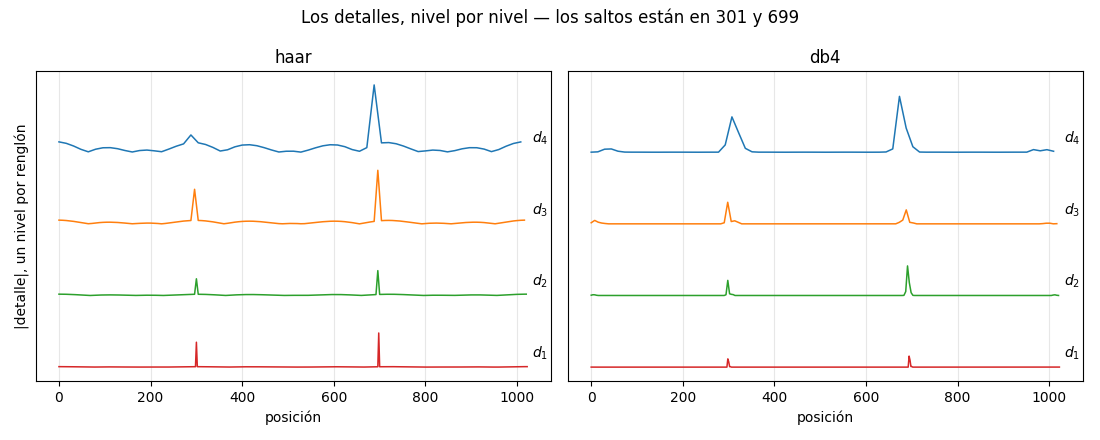

In [6]:
N = 1024
n = np.arange(N)
suave = np.sin(2 * np.pi * 2 * n / N) + 0.5 * np.sin(2 * np.pi * 5 * n / N)
señal = suave + 1.5 * (n >= 301) - 2.0 * (n >= 699)

NIVELES = 4
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)

for ax, familia in zip(axes, ["haar", "db4"]):
    coefs = pywt.wavedec(señal, familia, level=NIVELES)
    for j, d in enumerate(coefs[1:], start=1):      # d_4 (grueso) ... d_1 (fino)
        nivel = NIVELES + 1 - j
        pos = np.linspace(0, N, len(d), endpoint=False)
        ax.plot(pos, np.abs(d) + 3 * (nivel - 1), lw=1.1)
        ax.text(N + 8, 3 * (nivel - 1) + 0.4, f"$d_{nivel}$")
    ax.set_title(familia)
    ax.set_xlabel("posición")
    ax.set_yticks([])

axes[0].set_ylabel("|detalle|, un nivel por renglón")
fig.suptitle("Los detalles, nivel por nivel — los saltos están en 301 y 699")
plt.tight_layout()
plt.show()

Los coeficientes grandes están **clavados en 301 y en 699**, en todos los niveles: cada salto
deja una columna de detalles encendidos, y la posición de la columna dice dónde ocurrió. Eso es
localizar en tiempo y en escala a la vez — la DFT no puede decir nada parecido.

Y la diferencia entre paneles es la de la clase: en la parte suave, los renglones de **db4**
están apagados —sus cuatro momentos nulos anulan lo que localmente parece un polinomio— y los
de Haar todavía respiran, porque a Haar la sola pendiente ya lo enciende. Mismo argumento,
ahora medido.

---

## 3. El decaimiento de los detalles

La misma señal, tres análisis: Haar, db4, y la DCT — Fourier, para comparar. Ordenamos los
coeficientes de mayor a menor y miramos cómo caen, y cuánto error queda si nos quedamos con los
$M$ más grandes.

> **Predecí:** ¿cuál de las tres cae más rápido para *esta* señal? ¿Cambiaría sin los saltos?

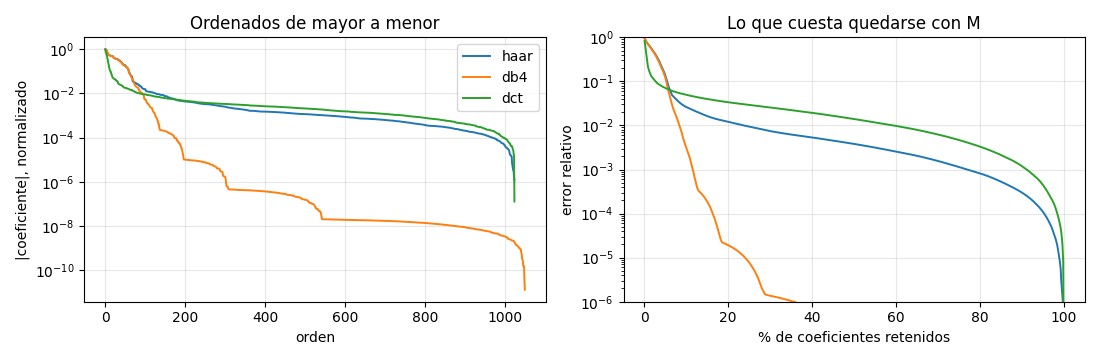

In [5]:
def coeficientes(x, familia):
    if familia == "dct":
        return fft.dct(x, norm="ortho")
    return np.concatenate(pywt.wavedec(x, familia, level=NIVELES))


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

for familia in ["haar", "db4", "dct"]:
    c = np.sort(np.abs(coeficientes(señal, familia)))[::-1]
    axes[0].semilogy(c / c[0], lw=1.4, label=familia)
    energia = np.cumsum(c**2)
    error = np.sqrt(1 - energia / energia[-1] + 1e-30)
    axes[1].semilogy(np.arange(1, len(c) + 1) / len(c) * 100, error, lw=1.4, label=familia)

axes[0].set_xlabel("orden")
axes[0].set_ylabel("|coeficiente|, normalizado")
axes[0].set_title("Ordenados de mayor a menor")
axes[1].set_xlabel("% de coeficientes retenidos")
axes[1].set_ylabel("error relativo")
axes[1].set_title("Lo que cuesta quedarse con M")
axes[1].set_ylim(1e-6, 1)
axes[0].legend()
plt.tight_layout()
plt.show()

Para esta señal —suave, con eventos— **db4 cae en picada**: sus cuatro momentos nulos apagan
todo lo que localmente parece un polinomio, y los saltos son unos pocos coeficientes por
nivel. Haar la sigue de lejos —su único momento nulo apaga menos— y la DCT cae lenta: los dos
saltos le cuestan a Fourier cientos de coeficientes, porque una discontinuidad derrama energía
sobre todas las frecuencias. La familia importa, y se elige por la señal.

El panel derecho es la misma información dicha como decisión: con el 5 % de los coeficientes
db4, el error ya es despreciable. **Tirar el 95 % puede costar menos que un vuelto** — y qué
tirar, cuánto cuesta, y por qué eso mismo quita ruido, es la clase que viene.